## Imports

In [13]:
import json
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


## Settings

In [14]:
# Visual style settings
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11

APPROACHES_CONFIG = [
    {'det': 'yolov8n', 'trk': 'bytetrack', 'name': 'YOLOv8n + ByteTrack'},
    {'det': 'yolov8n', 'trk': 'botsort', 'name': 'YOLOv8n + BoT-SORT'},
    {'det': 'yolov8s', 'trk': 'bytetrack', 'name': 'YOLOv8s + ByteTrack'},
    {'det': 'yolov8s', 'trk': 'botsort', 'name': 'YOLOv8s + BoT-SORT'},
]

## Paths resolving and preparation

In [15]:
# The split used to aggregate results: 'dev' (default) or 'test'.
# Set SPLIT=test before starting Jupyter, or change the value below.
SPLIT = 'test'


def find_root(start: Path) -> Path:
    """Walk up from `start` to the repository root (the folder with src/ and reports/)."""
    for d in (start, *start.parents):
        if (d / 'src').is_dir() and (d / 'reports').is_dir():
            return d
    raise FileNotFoundError(f'Repository root (with src/ and reports/) not found above {start}')


ROOT_DIR = find_root(Path.cwd().resolve())
reports_dir = ROOT_DIR / 'reports'
tracks_dir = ROOT_DIR / 'outputs' / 'tracks' / SPLIT
charts_dir = ROOT_DIR / 'scripts' / 'reports' / SPLIT / 'charts'
tables_dir = ROOT_DIR / 'scripts' / 'reports' / SPLIT / 'tables'
charts_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

print(f'Root: {ROOT_DIR}')
print(f'Split: {SPLIT}')
print(f'Charts: {charts_dir}')
print(f'Tables: {tables_dir}')


Root: C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\tracker\VehicleDetectionAndTrafficCounting
Split: test
Charts: C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\tracker\VehicleDetectionAndTrafficCounting\scripts\reports\test\charts
Tables: C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\tracker\VehicleDetectionAndTrafficCounting\scripts\reports\test\tables


## Directoty existence checking

In [16]:
if not reports_dir.exists():
  raise FileNotFoundError(
      f'Detector reports directory "{reports_dir}" not found in the project root, run the evaluation scripts'
  )

if not tracks_dir.exists():
  raise FileNotFoundError(
      f'Tracks directory "{tracks_dir}" not found, run run_tracking.py'
  )

## Tables preparation

In [17]:
rows = []
class_rows = []
detector_data = {}
print(f'Collecting metrics for 4 approaches... Split: {SPLIT.upper()}')


def percent(value):
    """Convert a 0..1 metric to percent; preserve missing values."""
    return round(float(value) * 100, 2) if value is not None else None


def macro_percent(values):
    values = [float(v) for v in values if v is not None and np.isfinite(float(v))]
    return round(float(np.mean(values)) * 100, 2) if values else None


# Read one detector report per model. Detection quality is detector-level, not tracker-level.
for detector in ('yolov8n', 'yolov8s'):
    det_json_path = reports_dir / f'detection_{detector}_{SPLIT}.json'
    if not det_json_path.exists():
        raise FileNotFoundError(
            f'Detector report not found: {det_json_path}. Run evaluate_detectors.py first.'
        )

    det_data = json.loads(det_json_path.read_text(encoding='utf-8'))
    detector_data[detector] = det_data

    for class_name, metrics in det_data.get('per_class', {}).items():
        if not isinstance(metrics, dict):
            continue
        class_rows.append({
            'Detector': detector,
            'Class': class_name,
            'TP': metrics.get('TP'),
            'FP': metrics.get('FP'),
            'FN': metrics.get('FN'),
            'Precision@0.25 (%)': percent(metrics.get('P@0.25')),
            'Recall@0.25 (%)': percent(metrics.get('R@0.25')),
            'F1@0.25 (%)': percent(metrics.get('F1@0.25')),
            'AP50_95 (%)': percent(metrics.get('AP50_95')),
        })

for item in APPROACHES_CONFIG:
    det_name = item['det']
    trk_name = item['trk']
    display_name = item['name']
    det_data = detector_data[det_name]

    # Locate the matching run's timing.json (take the most recently modified run if several exist).
    matching_dirs = list(tracks_dir.glob(f'{det_name}_{trk_name}_*'))
    if not matching_dirs:
        raise FileNotFoundError(
            f'Tracking results folder not found for {display_name} in {tracks_dir}. '
            'Run run_tracking.py first.'
        )
    target_track_dir = max(matching_dirs, key=lambda p: p.stat().st_mtime)
    timing_file = target_track_dir / 'timing.json'
    if not timing_file.exists():
        raise FileNotFoundError(f'timing.json not found: {timing_file}')
    timing_data = json.loads(timing_file.read_text(encoding='utf-8'))

    per_class = det_data.get('per_class', {})
    precisions = [m.get('P@0.25') for m in per_class.values() if isinstance(m, dict)]
    recalls = [m.get('R@0.25') for m in per_class.values() if isinstance(m, dict)]
    f1_scores = [m.get('F1@0.25') for m in per_class.values() if isinstance(m, dict)]

    rows.append({
        'Approach': display_name,
        'Detector': det_name,
        'Tracker': trk_name,
        'mAP_50 (%)': percent(det_data.get('mAP@0.5')),
        'mAP_50_95 (%)': percent(det_data.get('mAP@0.5:0.95')),
        'mAP_75 (%)': percent(det_data.get('mAP@0.75')),
        'Precision_macro (%)': macro_percent(precisions),
        'Recall_macro (%)': macro_percent(recalls),
        'F1_macro (%)': macro_percent(f1_scores),
        'FPS': round(float(timing_data.get('fps', 0) or 0), 2),
        'Latency_ms': round(float(timing_data.get('total_ms_per_frame', 0) or 0), 2),
    })

df = pd.DataFrame(rows)
class_df = pd.DataFrame(class_rows)

print('\nSummary table: four detector-tracker configurations')
print(df.to_markdown(index=False))

print('\nPer-class detection table')
if class_df.empty:
    print('No per-class metrics found. Check that detector evaluation was rerun.')
else:
    print(class_df.to_markdown(index=False))



Summary table: four detector-tracker configurations
| Approach            | Detector   | Tracker   |   mAP_50 (%) |   mAP_50_95 (%) |   mAP_75 (%) |   Precision_macro (%) |   Recall_macro (%) |   F1_macro (%) |    FPS |   Latency_ms |
|:--------------------|:-----------|:----------|-------------:|----------------:|-------------:|----------------------:|-------------------:|---------------:|-------:|-------------:|
| YOLOv8n + ByteTrack | yolov8n    | bytetrack |        71.77 |           49.54 |        61.31 |                 55.22 |              85.85 |          60.19 | 136.69 |         7.32 |
| YOLOv8n + BoT-SORT  | yolov8n    | botsort   |        71.77 |           49.54 |        61.31 |                 55.22 |              85.85 |          60.19 |  72.35 |        13.82 |
| YOLOv8s + ByteTrack | yolov8s    | bytetrack |        76.69 |           55.55 |        69.82 |                 58.03 |              88.99 |          64.52 | 105.51 |         9.48 |
| YOLOv8s + BoT-SORT  | yolov8s 

## Plots preparatrion

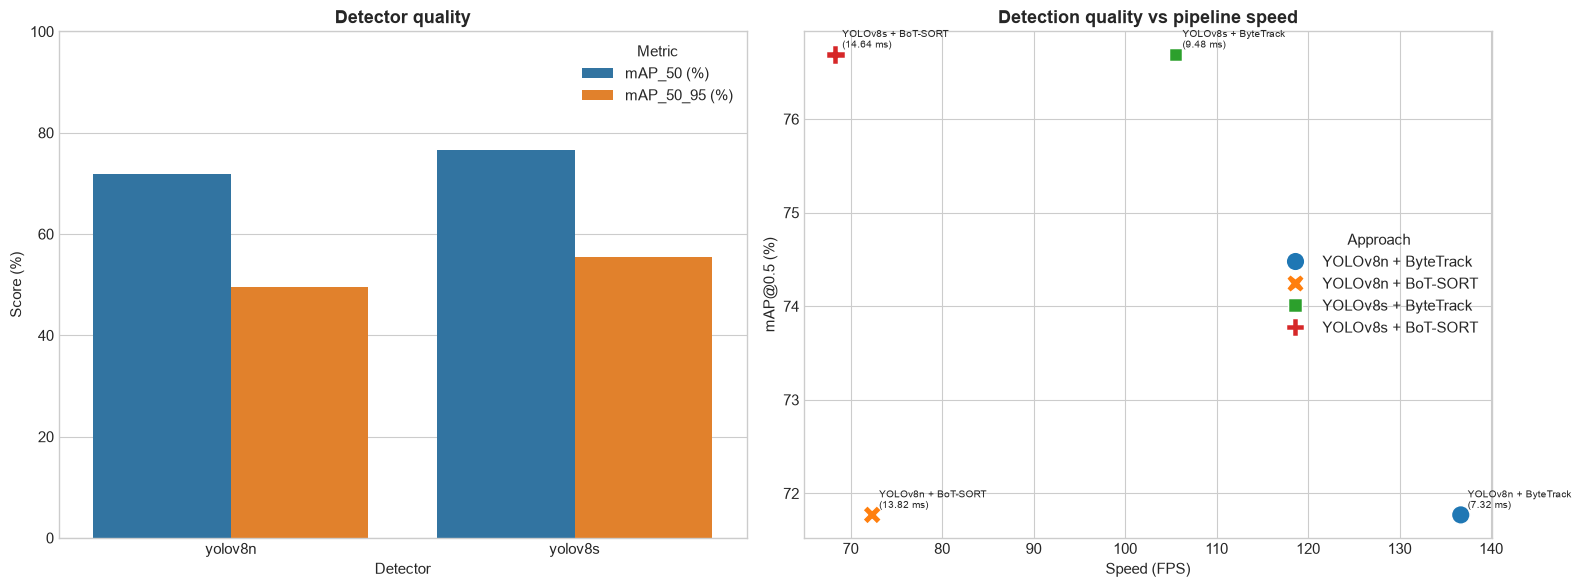

Saved: C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\tracker\VehicleDetectionAndTrafficCounting\scripts\reports\test\charts\models_comparison_charts_test.png


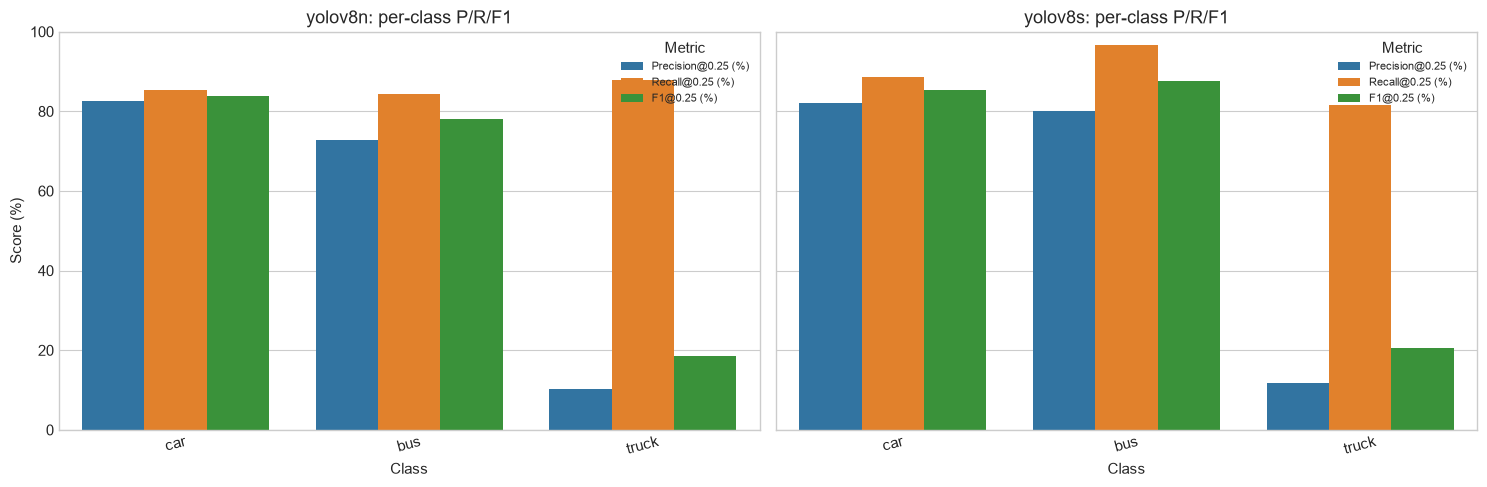

Saved: C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\tracker\VehicleDetectionAndTrafficCounting\scripts\reports\test\charts\detector_class_prf1_test.png


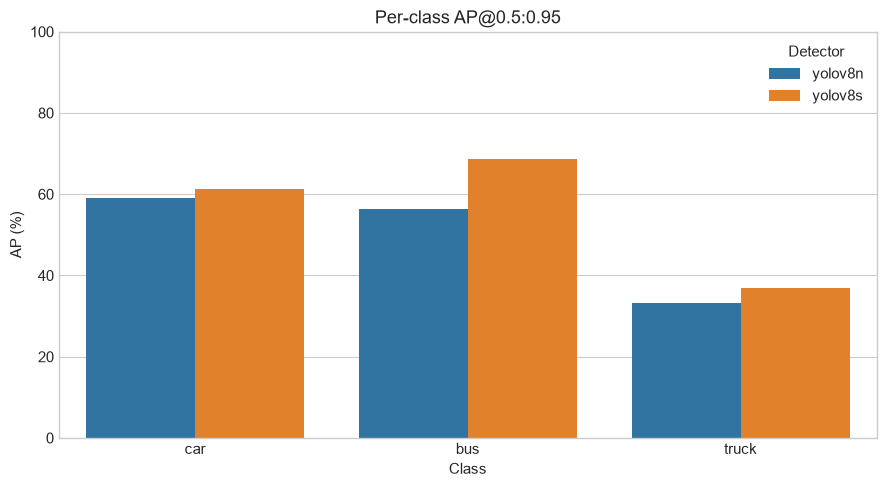

Saved: C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\tracker\VehicleDetectionAndTrafficCounting\scripts\reports\test\charts\detector_class_ap_test.png


In [18]:
# Figure 1: detector quality (one bar per detector) and pipeline speed-quality trade-off.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
detector_df = df.drop_duplicates('Detector').sort_values('Detector')
map_cols = ['mAP_50 (%)', 'mAP_50_95 (%)']
detector_melted = detector_df.melt(
    id_vars='Detector', value_vars=map_cols, var_name='Metric', value_name='Score (%)'
)
sns.barplot(data=detector_melted, x='Detector', y='Score (%)', hue='Metric', ax=axes[0])
axes[0].set_title('Detector quality', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Score (%)')
axes[0].set_ylim(0, 100)
axes[0].legend(title='Metric')

sns.scatterplot(
    data=df, x='FPS', y='mAP_50 (%)', hue='Approach', style='Approach', s=180, ax=axes[1]
)
axes[1].set_title('Detection quality vs pipeline speed', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Speed (FPS)')
axes[1].set_ylabel('mAP@0.5 (%)')
for _, row in df.iterrows():
    axes[1].annotate(
        f"{row['Approach']}\n({row['Latency_ms']} ms)",
        (row['FPS'], row['mAP_50 (%)']),
        xytext=(5, 5), textcoords='offset points', fontsize=7
    )
plt.tight_layout()
summary_plot = charts_dir / f'models_comparison_charts_{SPLIT}.png'
plt.savefig(summary_plot, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {summary_plot}')

# Figure 2: per-class Precision, Recall and F1, separately for each detector.
if not class_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
    prf_cols = ['Precision@0.25 (%)', 'Recall@0.25 (%)', 'F1@0.25 (%)']
    for ax, detector in zip(axes, ('yolov8n', 'yolov8s')):
        part = class_df[class_df['Detector'] == detector]
        plot_data = part.melt(
            id_vars='Class', value_vars=prf_cols, var_name='Metric', value_name='Score (%)'
        )
        sns.barplot(data=plot_data, x='Class', y='Score (%)', hue='Metric', ax=ax)
        ax.set_title(f'{detector}: per-class P/R/F1')
        ax.set_xlabel('Class')
        ax.set_ylabel('Score (%)')
        ax.set_ylim(0, 100)
        ax.tick_params(axis='x', rotation=15)
        ax.legend(title='Metric', fontsize=8)
    plt.tight_layout()
    prf_plot = charts_dir / f'detector_class_prf1_{SPLIT}.png'
    plt.savefig(prf_plot, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved: {prf_plot}')

    # Figure 3: per-class AP averaged over IoU thresholds 0.50:0.95.
    ap_data = class_df.dropna(subset=['AP50_95 (%)'])
    if not ap_data.empty:
        fig, ax = plt.subplots(figsize=(9, 5))
        sns.barplot(data=ap_data, x='Class', y='AP50_95 (%)', hue='Detector', ax=ax)
        ax.set_title('Per-class AP@0.5:0.95')
        ax.set_ylabel('AP (%)')
        ax.set_xlabel('Class')
        ax.set_ylim(0, 100)
        ax.legend(title='Detector')
        plt.tight_layout()
        ap_plot = charts_dir / f'detector_class_ap_{SPLIT}.png'
        plt.savefig(ap_plot, dpi=300, bbox_inches='tight')
        plt.show()
        print(f'Saved: {ap_plot}')


## Saving the results

In [19]:
# Save the summary comparison table (CSV, Markdown and LaTeX).
summary_csv = tables_dir / f'metrics_table_{SPLIT}.csv'
summary_md = tables_dir / f'metrics_table_{SPLIT}.md'
summary_tex = tables_dir / f'metrics_table_{SPLIT}.tex'
df.to_csv(summary_csv, index=False)
df.to_markdown(summary_md, index=False)
summary_tex.write_text(
    df.to_latex(
        index=False,
        float_format='%.2f',
        caption='Comparison of detector quality and pipeline speed for four configurations',
        label=f'tab:models_comparison_{SPLIT}',
    ),
    encoding='utf-8',
)

# Save the detailed per-class detector table, including the new TP/FP/FN/F1 fields.
class_csv = tables_dir / f'detector_per_class_{SPLIT}.csv'
class_md = tables_dir / f'detector_per_class_{SPLIT}.md'
class_df.to_csv(class_csv, index=False)
class_df.to_markdown(class_md, index=False)

print('Saved tables:')
for path in (summary_csv, summary_md, summary_tex, class_csv, class_md):
    print(f' - {path}')


Saved tables:
 - C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\tracker\VehicleDetectionAndTrafficCounting\scripts\reports\test\tables\metrics_table_test.csv
 - C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\tracker\VehicleDetectionAndTrafficCounting\scripts\reports\test\tables\metrics_table_test.md
 - C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\tracker\VehicleDetectionAndTrafficCounting\scripts\reports\test\tables\metrics_table_test.tex
 - C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\tracker\VehicleDetectionAndTrafficCounting\scripts\reports\test\tables\detector_per_class_test.csv
 - C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\tracker\VehicleDetectionAndTrafficCounting\scripts\reports\test\tables\detector_per_class_test.md
